In [5]:
!pip install -q transformers datasets accelerate evaluate scikit-learn pandas numpy matplotlib seaborn torch

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import time

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [7]:
from datasets import load_dataset
import pandas as pd

# Load Amazon Reviews dataset from Hugging Face
dataset = load_dataset("goosmanlei/amazon_reviews_multi", "en")

# Convert training data into DataFrame
df = pd.DataFrame(dataset["train"])

# Display dataset information
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

df.head()

Dataset shape: (200000, 8)
Columns: ['review_id', 'product_id', 'reviewer_id', 'stars', 'review_body', 'review_title', 'language', 'product_category']


,review_id,product_id,reviewer_id,stars,review_body,review_title,language,product_category
0,en_0964290,product_en_0740675,reviewer_en_0342986,1,Arrived broken. Manufacturer defect. Two of th...,I'll spend twice the amount of time boxing up ...,en,furniture
1,en_0690095,product_en_0440378,reviewer_en_0133349,1,the cabinet dot were all detached from backing...,Not use able,en,home_improvement
2,en_0311558,product_en_0399702,reviewer_en_0152034,1,I received my first order of this product and ...,The product is junk.,en,home
3,en_0044972,product_en_0444063,reviewer_en_0656967,1,This product is a piece of shit. Do not buy. D...,Fucking waste of money,en,wireless
4,en_0784379,product_en_0139353,reviewer_en_0757638,1,went through 3 in one day doesn't fit correct ...,bubble,en,pc


In [9]:

# Total number of reviews
print("Total reviews:", len(df))

# Check missing values
print("\nMissing values:")
print(df[['review_body', 'stars']].isnull().sum())

# Rating distribution
print("\nRating distribution:")
print(df['stars'].value_counts().sort_index())

# Display first 5 reviews
df[['review_body', 'stars']].head()


Total reviews: 200000

Missing values:
review_body    0
stars          0
dtype: int64

Rating distribution:
stars
1    40000
2    40000
3    40000
4    40000
5    40000
Name: count, dtype: int64


,review_body,stars
0,Arrived broken. Manufacturer defect. Two of th...,1
1,the cabinet dot were all detached from backing...,1
2,I received my first order of this product and ...,1
3,This product is a piece of shit. Do not buy. D...,1
4,went through 3 in one day doesn't fit correct ...,1


In [11]:
def get_sentiment(stars):
    if stars <= 2:
        return "Negative"
    elif stars == 3:
        return "Neutral"
    else:
        return "Positive"

# Create sentiment column
df['Sentiment'] = df['stars'].apply(get_sentiment)

print("Sentiment distribution:")
print(df['Sentiment'].value_counts())

print("\nSample reviews:")
display(df[['review_body', 'stars', 'Sentiment']].head(10))


Sentiment distribution:
Sentiment
Negative    80000
Positive    80000
Neutral     40000
Name: count, dtype: int64

Sample reviews:


,review_body,stars,Sentiment
0,Arrived broken. Manufacturer defect. Two of th...,1,Negative
1,the cabinet dot were all detached from backing...,1,Negative
2,I received my first order of this product and ...,1,Negative
3,This product is a piece of shit. Do not buy. D...,1,Negative
4,went through 3 in one day doesn't fit correct ...,1,Negative
5,Poor quality. The material was fuzzy from day ...,1,Negative
6,Ordered 2 they shipped 1 promised by certain d...,1,Negative
7,"Followed directions, did not work as advertised.",1,Negative
8,There is a terribly done band across the top. ...,1,Negative
9,"Unless you have this jam-packed full of items,...",1,Negative


In [13]:

sentiment_mapping = {
    "Negative": 0,
    "Neutral": 1,
    "Positive": 2
}

# Convert sentiment into numerical labels
df['Label'] = df['Sentiment'].map(sentiment_mapping)

print("Sentiment labels created successfully!")

display(df[['review_body', 'stars', 'Sentiment', 'Label']].head())


Sentiment labels created successfully!


,review_body,stars,Sentiment,Label
0,Arrived broken. Manufacturer defect. Two of th...,1,Negative,0
1,the cabinet dot were all detached from backing...,1,Negative,0
2,I received my first order of this product and ...,1,Negative,0
3,This product is a piece of shit. Do not buy. D...,1,Negative,0
4,went through 3 in one day doesn't fit correct ...,1,Negative,0


In [14]:

df = df[['review_body', 'Sentiment', 'Label']].copy()

df.drop_duplicates(subset=['review_body'], inplace=True)
df.dropna(subset=['review_body', 'Label'], inplace=True)

df = df.reset_index(drop=True)

print("Final dataset shape:", df.shape)
print("\nFinal sentiment distribution:")
print(df['Sentiment'].value_counts())


Final dataset shape: (199426, 3)

Final sentiment distribution:
Sentiment
Negative    79819
Positive    79700
Neutral     39907
Name: count, dtype: int64


In [15]:

from sklearn.model_selection import train_test_split

# Select 5000 reviews
df_fast, _ = train_test_split(
    df,
    train_size=5000,
    stratify=df['Label'],
    random_state=42
)

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    df_fast['review_body'],
    df_fast['Label'],
    test_size=0.2,
    stratify=df_fast['Label'],
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 4000
Testing samples: 1000


In [16]:
from transformers import AutoTokenizer

MODEL_NAME = "bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("BERT tokenizer loaded successfully!")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

BERT tokenizer loaded successfully!


In [17]:
MAX_LENGTH = 96

train_encodings = tokenizer(
    X_train.tolist(),
    truncation=True,
    padding="max_length",
    max_length=MAX_LENGTH
)

test_encodings = tokenizer(
    X_test.tolist(),
    truncation=True,
    padding="max_length",
    max_length=MAX_LENGTH
)

In [18]:
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

print("BERT model loaded successfully!")
print("Device:", device)

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT model loaded successfully!
Device: cuda


In [19]:
from torch.utils.data import Dataset, DataLoader

class ReviewDataset(Dataset):

    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = list(labels)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {
            'input_ids': torch.tensor(self.encodings['input_ids'][idx]),
            'attention_mask': torch.tensor(self.encodings['attention_mask'][idx]),
            'labels': torch.tensor(self.labels[idx], dtype=torch.long)
        }

train_dataset = ReviewDataset(train_encodings, y_train)
test_dataset = ReviewDataset(test_encodings, y_test)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64)

print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))

Training batches: 125
Testing batches: 16


In [20]:
from torch.optim import AdamW
from tqdm.auto import tqdm
import time
import torch

optimizer = AdamW(model.parameters(), lr=2e-5)

EPOCHS = 5

epoch_losses = []
start_time = time.time()

for epoch in range(EPOCHS):

    model.train()
    total_loss = 0

    progress_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{EPOCHS}"
    )

    for batch in progress_bar:

        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        optimizer.zero_grad()

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=torch.cuda.is_available()
        ):

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            loss = outputs.loss

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        progress_bar.set_postfix(loss=loss.item())

    avg_loss = total_loss / len(train_loader)
    epoch_losses.append(avg_loss)

    print(f"Epoch {epoch+1} Average Loss: {avg_loss:.4f}")

training_time = time.time() - start_time

print("\nBERT training completed!")
print("Total training time:", round(training_time, 2), "seconds")

Epoch 1/5:   0%|          | 0/125 [00:00<?, ?it/s]

Epoch 1 Average Loss: 0.8857


Epoch 2/5:   0%|          | 0/125 [00:00<?, ?it/s]

Epoch 2 Average Loss: 0.5695


Epoch 3/5:   0%|          | 0/125 [00:00<?, ?it/s]

Epoch 3 Average Loss: 0.4119


Epoch 4/5:   0%|          | 0/125 [00:00<?, ?it/s]

Epoch 4 Average Loss: 0.2513


Epoch 5/5:   0%|          | 0/125 [00:00<?, ?it/s]

Epoch 5 Average Loss: 0.1815

BERT training completed!
Total training time: 96.83 seconds


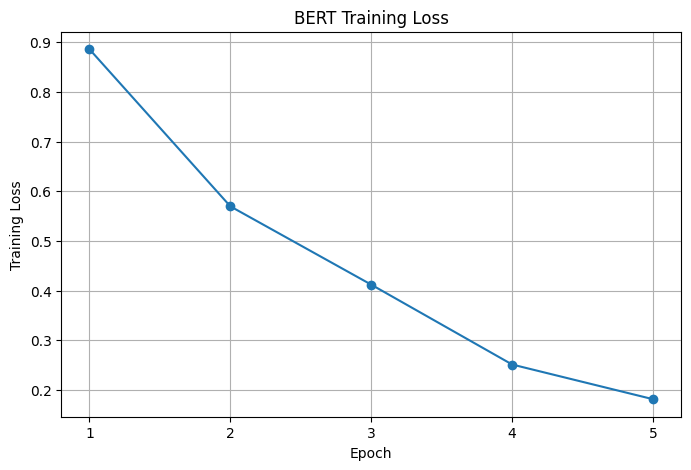

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, EPOCHS + 1),
    epoch_losses,
    marker='o'
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("BERT Training Loss")
plt.xticks(range(1, EPOCHS + 1))
plt.grid(True)
plt.show()

In [22]:
model.save_pretrained("/content/bert_sentiment_model")
tokenizer.save_pretrained("/content/bert_sentiment_model")

print("BERT model saved successfully!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

BERT model saved successfully!


In [23]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

model.eval()

all_predictions = []
all_labels = []

start_eval = time.time()

with torch.no_grad():

    for batch in tqdm(test_loader, desc="Evaluating BERT"):

        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        predictions = torch.argmax(outputs.logits, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(batch['labels'].numpy())

bert_eval_time = time.time() - start_eval

print("BERT Accuracy:", accuracy_score(all_labels, all_predictions))
print("BERT Precision:", precision_score(all_labels, all_predictions, average='weighted'))
print("BERT Recall:", recall_score(all_labels, all_predictions, average='weighted'))
print("BERT F1 Score:", f1_score(all_labels, all_predictions, average='weighted'))

print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_predictions,
    target_names=["Negative", "Neutral", "Positive"]
))

print("Evaluation time:", round(bert_eval_time, 2), "seconds")

Evaluating BERT:   0%|          | 0/16 [00:00<?, ?it/s]

BERT Accuracy: 0.731
BERT Precision: 0.7380233423259276
BERT Recall: 0.731
BERT F1 Score: 0.7339664236216663

Classification Report:
              precision    recall  f1-score   support

    Negative       0.77      0.79      0.78       400
     Neutral       0.43      0.46      0.44       200
    Positive       0.87      0.81      0.84       400

    accuracy                           0.73      1000
   macro avg       0.69      0.69      0.69      1000
weighted avg       0.74      0.73      0.73      1000

Evaluation time: 5.45 seconds


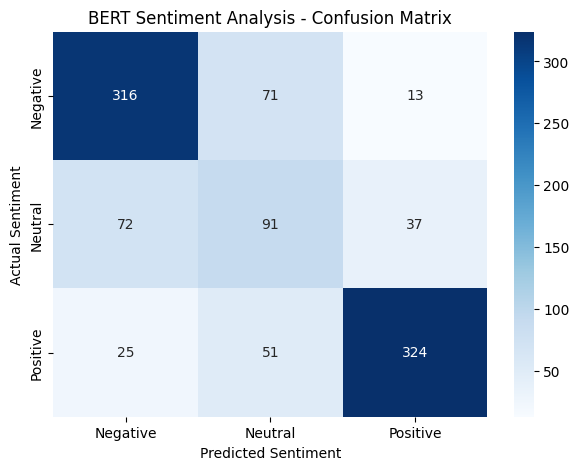

In [24]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(all_labels, all_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negative', 'Neutral', 'Positive'],
    yticklabels=['Negative', 'Neutral', 'Positive']
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("BERT Sentiment Analysis - Confusion Matrix")
plt.show()

In [25]:
import re
from collections import Counter

MAX_VOCAB = 20000
MAX_LEN = 96

def tokenize_text(text):
    return re.findall(r'\b\w+\b', text.lower())

# Build vocabulary using training reviews only
word_counts = Counter()

for review in X_train:
    word_counts.update(tokenize_text(review))

vocab = {
    word: idx + 2
    for idx, (word, count) in enumerate(word_counts.most_common(MAX_VOCAB))
}

vocab["<PAD>"] = 0
vocab["<UNK>"] = 1

print("Vocabulary size:", len(vocab))

Vocabulary size: 8785


In [26]:
def encode_reviews(reviews):
    sequences = []

    for review in reviews:
        tokens = tokenize_text(review)
        sequence = [vocab.get(word, 1) for word in tokens[:MAX_LEN]]

        sequence += [0] * (MAX_LEN - len(sequence))

        sequences.append(sequence)

    return torch.tensor(sequences, dtype=torch.long)

X_train_lstm = encode_reviews(X_train)
X_test_lstm = encode_reviews(X_test)

y_train_lstm = torch.tensor(y_train.to_numpy(), dtype=torch.long)
y_test_lstm = torch.tensor(y_test.to_numpy(), dtype=torch.long)

print("Training shape:", X_train_lstm.shape)
print("Testing shape:", X_test_lstm.shape)

Training shape: torch.Size([4000, 96])
Testing shape: torch.Size([1000, 96])


In [27]:
from torch.utils.data import TensorDataset, DataLoader

train_lstm_dataset = TensorDataset(X_train_lstm, y_train_lstm)
test_lstm_dataset = TensorDataset(X_test_lstm, y_test_lstm)

train_lstm_loader = DataLoader(
    train_lstm_dataset,
    batch_size=64,
    shuffle=True
)

test_lstm_loader = DataLoader(
    test_lstm_dataset,
    batch_size=128,
    shuffle=False
)

print("LSTM training batches:", len(train_lstm_loader))
print("LSTM testing batches:", len(test_lstm_loader))

LSTM training batches: 63
LSTM testing batches: 8


In [28]:
import torch.nn as nn

class LSTMSentiment(nn.Module):

    def __init__(self, vocab_size, embedding_dim=128,
                 hidden_dim=128, num_classes=3):

        super(LSTMSentiment, self).__init__()

        self.embedding = nn.Embedding(
            vocab_size, embedding_dim, padding_idx=0
        )

        self.lstm = nn.LSTM(
            embedding_dim,
            hidden_dim,
            batch_first=True,
            bidirectional=True
        )

        self.dropout = nn.Dropout(0.3)

        self.fc = nn.Linear(hidden_dim * 2, num_classes)

    def forward(self, x):

        embedded = self.embedding(x)

        _, (hidden, _) = self.lstm(embedded)

        hidden_forward = hidden[-2]
        hidden_backward = hidden[-1]

        combined = torch.cat(
            (hidden_forward, hidden_backward), dim=1
        )

        combined = self.dropout(combined)

        return self.fc(combined)


lstm_model = LSTMSentiment(
    vocab_size=len(vocab)
).to(device)

print(lstm_model)

LSTMSentiment(
  (embedding): Embedding(8785, 128, padding_idx=0)
  (lstm): LSTM(128, 128, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=256, out_features=3, bias=True)
)


In [29]:
import torch.optim as optim
from tqdm.auto import tqdm
import time

criterion = nn.CrossEntropyLoss()

optimizer_lstm = optim.Adam(
    lstm_model.parameters(),
    lr=0.001
)

EPOCHS = 5
lstm_losses = []

start_time = time.time()

for epoch in range(EPOCHS):

    lstm_model.train()
    total_loss = 0

    for reviews, labels in tqdm(
        train_lstm_loader,
        desc=f"Epoch {epoch+1}/{EPOCHS}"
    ):

        reviews = reviews.to(device)
        labels = labels.to(device)

        optimizer_lstm.zero_grad()

        outputs = lstm_model(reviews)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer_lstm.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(train_lstm_loader)
    lstm_losses.append(avg_loss)

    print(f"Epoch {epoch+1} Loss: {avg_loss:.4f}")

lstm_training_time = time.time() - start_time

print("\nLSTM training completed!")
print("Training time:", round(lstm_training_time, 2), "seconds")

Epoch 1/5:   0%|          | 0/63 [00:00<?, ?it/s]

Epoch 1 Loss: 1.0184


Epoch 2/5:   0%|          | 0/63 [00:00<?, ?it/s]

Epoch 2 Loss: 0.8685


Epoch 3/5:   0%|          | 0/63 [00:00<?, ?it/s]

Epoch 3 Loss: 0.7559


Epoch 4/5:   0%|          | 0/63 [00:00<?, ?it/s]

Epoch 4 Loss: 0.6401


Epoch 5/5:   0%|          | 0/63 [00:00<?, ?it/s]

Epoch 5 Loss: 0.5922

LSTM training completed!
Training time: 2.9 seconds


In [30]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

lstm_model.eval()

lstm_predictions = []
lstm_actual = []

start_eval = time.time()

with torch.no_grad():

    for reviews, labels in test_lstm_loader:

        reviews = reviews.to(device)

        outputs = lstm_model(reviews)

        predictions = torch.argmax(outputs, dim=1)

        lstm_predictions.extend(predictions.cpu().numpy())
        lstm_actual.extend(labels.numpy())

lstm_eval_time = time.time() - start_eval

print("LSTM Accuracy:",
      accuracy_score(lstm_actual, lstm_predictions))

print("LSTM Precision:",
      precision_score(lstm_actual, lstm_predictions, average='weighted'))

print("LSTM Recall:",
      recall_score(lstm_actual, lstm_predictions, average='weighted'))

print("LSTM F1 Score:",
      f1_score(lstm_actual, lstm_predictions, average='weighted'))

print("\nClassification Report:")

print(classification_report(
    lstm_actual,
    lstm_predictions,
    target_names=["Negative", "Neutral", "Positive"]
))

print("Evaluation time:", round(lstm_eval_time, 2), "seconds")

LSTM Accuracy: 0.608
LSTM Precision: 0.5869859335633675
LSTM Recall: 0.608
LSTM F1 Score: 0.5906358525720218

Classification Report:
              precision    recall  f1-score   support

    Negative       0.60      0.75      0.67       400
     Neutral       0.31      0.18      0.23       200
    Positive       0.71      0.68      0.69       400

    accuracy                           0.61      1000
   macro avg       0.54      0.54      0.53      1000
weighted avg       0.59      0.61      0.59      1000

Evaluation time: 0.08 seconds


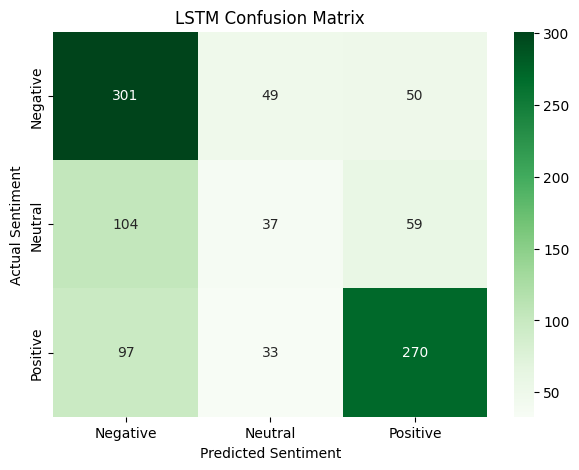

In [31]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_lstm = confusion_matrix(lstm_actual, lstm_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_lstm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Negative', 'Neutral', 'Positive'],
    yticklabels=['Negative', 'Neutral', 'Positive']
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("LSTM Confusion Matrix")
plt.show()

In [32]:
print("BERT Training Time:", round(training_time, 2), "seconds")
print("LSTM Training Time:", round(lstm_training_time, 2), "seconds")

BERT Training Time: 96.83 seconds
LSTM Training Time: 2.9 seconds
